# Projeto Integrador - AeroMotion Dynamics
## Etapa 3: Visão Computacional Multimodal (Inspeção Geométrica e Térmica)

Este notebook valida a camada de visão artificial para inspeção de componentes de turbinas:
1. **Inspeção Geométrica (Óptica)**: Suavização gaussiana, conversão para tons de cinza, deteção de bordas com Canny e cálculo de circularidade/área para separar peças conformes de peças com deformação mecânica.
2. **Inspeção Térmica (Infravermelho)**: Conversão para espaço de cor HSV e limiarização (*thresholding*) morfológica para isolar e quantificar zonas de sobreaquecimento crítico (*hotspots*).

In [1]:
import os
from pathlib import Path
import sys

# Garante o carregamento dos módulos a partir da raiz do repositório
caminho_raiz = Path.cwd().parent
if str(caminho_raiz) not in sys.path:
  sys.path.append(str(caminho_raiz))
os.chdir(caminho_raiz)

import cv2
import matplotlib.pyplot as plt
import numpy as np
from src.vision.geometric_inspector import GeometricInspector
from src.vision.thermal_inspector import ThermalInspector

print(f"Diretório ativo configurado: {os.getcwd()}")

Diretório ativo configurado: c:\Users\andre_matteussi\Documents\GitHub\aeromotion-predictive-system


## 1. Inspeção Geométrica e Dimensional (Canny Edge Detection)

A integridade estrutural das pás e flanges é avaliada pela regularidade do contorno e pelo fator de circularidade:
$$C = \frac{4 \pi \cdot \text{Área}}{\text{Perímetro}^2}$$

- Para uma geometria circular ideal, $C \approx 1.0$.
- Componentes com empenamento, trincas ou rebarbas apresentam perda de área útil e irregularidade perimetral ($C < 0.40$ ou área fora da tolerância), resultando em reprovação imediata.

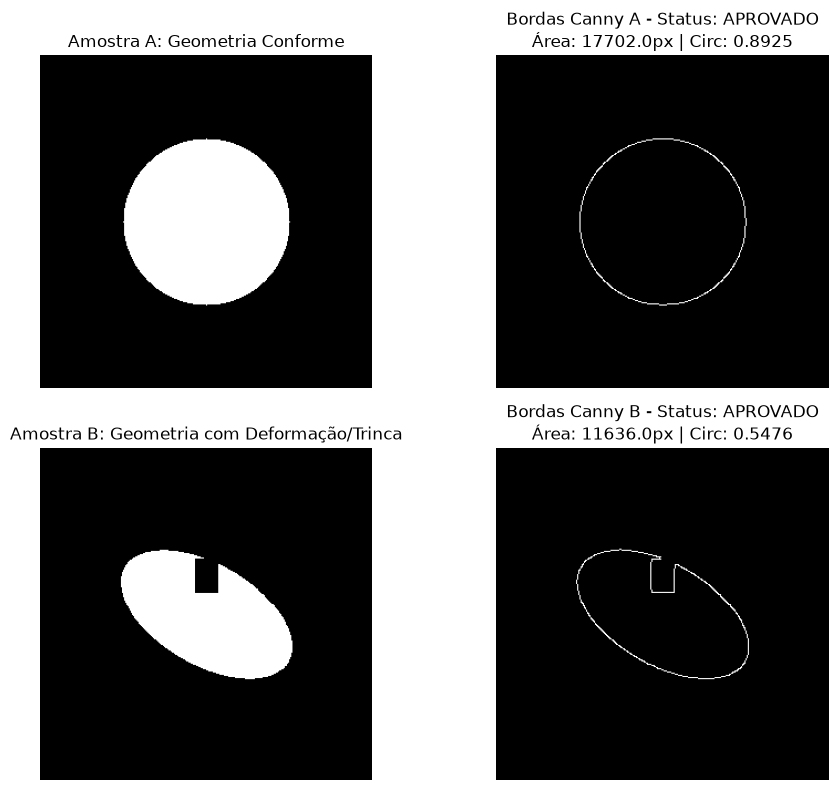

In [ ]:
inspetor_geom = GeometricInspector(
    blur_ksize=(5, 5),
    canny_low=50,
    canny_high=150,
    min_circularity=0.80,
    min_area_px=15000.0,
)

# 1. Peça Perfeita (Circular e simétrica)
peca_conforme = np.zeros((300, 300, 3), dtype=np.uint8)
cv2.circle(peca_conforme, (150, 150), 75, (255, 255, 255), -1)

# 2. Peça com Defeito Estrutural (Deformada / Ovalizada com entalhe)
peca_defeito = np.zeros((300, 300, 3), dtype=np.uint8)
cv2.ellipse(peca_defeito, (150, 150), (85, 45), 30, 0, 360, (255, 255, 255), -1)
cv2.rectangle(
    peca_defeito, (140, 100), (160, 130), (0, 0, 0), -1
)  # Falha / trinca mecânica

# Execução das inspeções
res_conforme = inspetor_geom.inspecionar_geometria(peca_conforme)
res_defeito = inspetor_geom.inspecionar_geometria(peca_defeito)

# Visualização comparativa
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].imshow(peca_conforme)
axes[0, 0].set_title("Amostra A: Geometria Conforme")
axes[0, 0].axis("off")

axes[0, 1].imshow(res_conforme["mascara_bordas"], cmap="gray")
axes[0, 1].set_title(
    f"Bordas Canny A - Status: {'APROVADO' if res_conforme['aprovado'] else 'REPROVADO'}\n"
    f"Área: {res_conforme['area_px']}px | Circ: {res_conforme['circularidade']}"
)
axes[0, 1].axis("off")

axes[1, 0].imshow(peca_defeito)
axes[1, 0].set_title("Amostra B: Geometria com Deformação/Trinca")
axes[1, 0].axis("off")

axes[1, 1].imshow(res_defeito["mascara_bordas"], cmap="gray")
axes[1, 1].set_title(
    f"Bordas Canny B - Status: {'APROVADO' if res_defeito['aprovado'] else 'REPROVADO'}\n"
    f"Área: {res_defeito['area_px']}px | Circ: {res_defeito['circularidade']}"
)
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

## 2. Inspeção Térmica Infravermelha (Espaço de Cor HSV & Hotspots)

Para detectar anomalias provocadas por atrito excessivo em mancais ou cavitação:
- A imagem termográfica é convertida de BGR para **HSV** (*Hue, Saturation, Value*), desacoplando a intensidade luminosa da tonalidade de calor.
- A faixa de matiz crítico (tons avermelhados de alta temperatura) é isolada por limiarização e filtrada morfologicamente para descartar reflexos espúrios.
- Caso a área acumulada de pontos quentes ultrapasse o limiar operacional ($300\text{ px}$), dispara-se o alarme de sobreaquecimento.

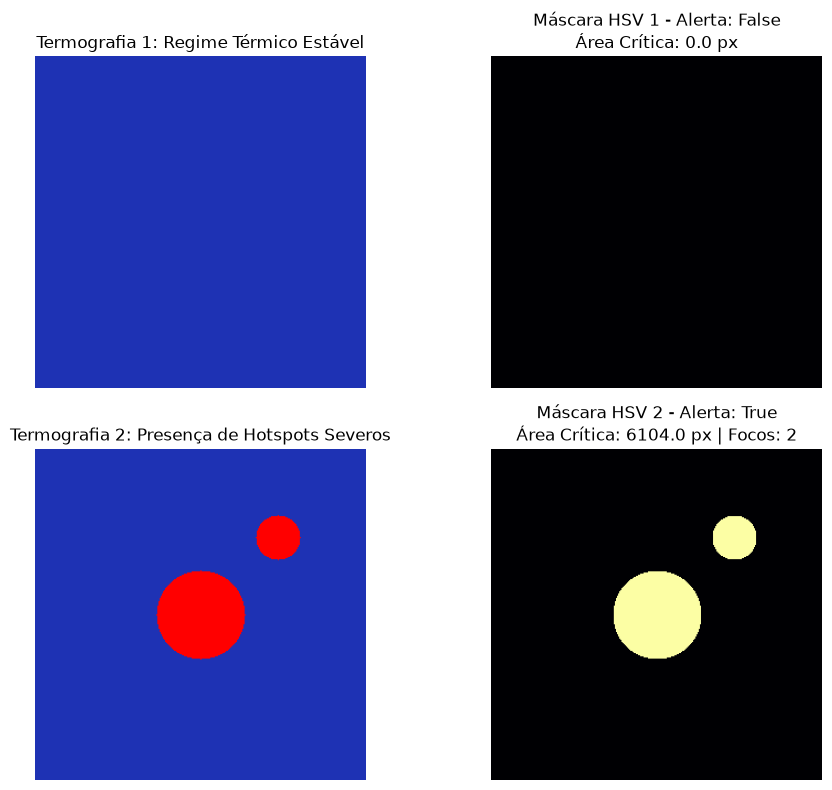

In [3]:
inspetor_term = ThermalInspector(limiar_area_critica_px=300.0)

# 1. Termografia Nominal (Distribuição de calor uniforme e amena)
term_normal = np.zeros((300, 300, 3), dtype=np.uint8)
term_normal[:, :] = [180, 50, 30]  # Fundo térmico frio/estável em tons azuis

# 2. Termografia com Sobreaquecimento Severo (Hotspot concentrado)
term_critica = np.zeros((300, 300, 3), dtype=np.uint8)
term_critica[:, :] = [180, 50, 30]
# Adição de foco crítico com alta saturação vermelha
cv2.circle(term_critica, (150, 150), 40, (0, 0, 255), -1)
cv2.circle(term_critica, (220, 80), 20, (0, 0, 255), -1)

# Execução das análises
res_term_normal = inspetor_term.detetar_hotspots(term_normal)
res_term_critica = inspetor_term.detetar_hotspots(term_critica)

# Visualização comparativa
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].imshow(cv2.cvtColor(term_normal, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Termografia 1: Regime Térmico Estável")
axes[0, 0].axis("off")

axes[0, 1].imshow(res_term_normal["mascara_termica"], cmap="inferno")
axes[0, 1].set_title(
    f"Máscara HSV 1 - Alerta: {res_term_normal['alerta_sobreaquecimento']}\n"
    f"Área Crítica: {res_term_normal['area_critica_px']} px"
)
axes[0, 1].axis("off")

axes[1, 0].imshow(cv2.cvtColor(term_critica, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title("Termografia 2: Presença de Hotspots Severos")
axes[1, 0].axis("off")

axes[1, 1].imshow(res_term_critica["mascara_termica"], cmap="inferno")
axes[1, 1].set_title(
    f"Máscara HSV 2 - Alerta: {res_term_critica['alerta_sobreaquecimento']}\n"
    f"Área Crítica: {res_term_critica['area_critica_px']} px | Focos: {res_term_critica['quantidade_focos']}"
)
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

### Conclusões da Validação de Visão Computacional
- O algoritmo Canny combinado com o cálculo de circularidade permitiu diferenciar peças com tolerância geométrica estrita daquelas com avarias de usinagem.
- A segmentação no espaço de cor HSV isolou com precisão os focos de sobreaquecimento, gerando métricas de área crítica para alimentar os alarmes dos sistemas SCADA e da API FastAPI no nó de Edge Computing.